## This notebook contains one example method to deform cell shapes.

In this notebook, forces are generated on the cell surface following a phenomenological model inspired by vertex modelling and a continuum mechanics model for following shapes, e.g. https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1008592 . Here we treat the cells as capable of shape changes through adhering to the surface at the boundary. The substrate is divided up in to many small locations where a molecular can be adhered. 

This is far from the only model that can be implemented; a wide variety of approaches exist including but not limited to:

Cellular potts models, https://pubmed.ncbi.nlm.nih.gov/36587108/ ,  https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.132.248401

Phase field models https://www.nature.com/articles/s41540-023-00265-w
https://www.nature.com/articles/npjcompumats201619?WT.feed_name=subjects_biomaterials

Immersed boundary methods:https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0162474

Active shell theory, https://iopscience.iop.org/article/10.1088/1367-2630/16/6/065005

among many others. This notebook contains code to implement a phenomenological model inspired from continuum mechanics and vertex theory. The background to the adherence theory was covered in the other notebook, and the simulations within this notebook are less structured. Some example questions are below, but feel free to explore as you wish, or as inspired by your experimental data.
        

## How does substrate stiffness affect cell spreading?

Vary $\alpha$ and/or linker strength through various values, to see how final cell area changes and what shapes emerge.


## What determines whether a cell is circular or elongated?

In vertex models, the ratio of area and perimeter terms are known to affect final shapes significantly, vary $K_A, K_P$ and see how having higher or lower values for each affects final cell shapes.

## What is the role of bending stiffness?

The model below has a bending penalty term; what effect does the inclusion of this have on the cell shapes/morphology?

## In the 1D case we looked at different types of linker bonds (i.e. catch slip bonds). The current version below doesn't implement these- what effects do you expect changing binding/unbinding rates to have? This effectively tests effect of cell adhesion on spreading.

(Try varying cell binding rates $k_on$ to study this)

## How does linker lifetime influence cell morphology? Does the lifetime of cell–substrate adhesions influence cell shape?

(By varying cell unbinding rates, you change the lifetime of adhesions, does this affect hte cell shape changes?)


## Where do adhesions form on a migrating cell?
 The code below has front biased binding through the value $\beta$. Larger values result in more front biased binding - is this the case in the experiments? Can you otherwise compare the distribution in the experimental images of adhesion sites?

## Preamble:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.optimize import least_squares


![ExampleOfCell2DSimFigure](diagrams/cell_diagram_2d.png)

## Functions:


Inspired by vertex modelling formulations, the energy of a cell that is not interacting with other cells can be written in terms of the perimeter (P) and area (A) of the cell, relative to some preferred configurations $(P_0 , A_0)$:

$$E_{cell} = \frac{k_a}{2} (A_{cell}-A_0)^2+\frac{k_p}{2} (P_{cell}-P_0)^2$$

This equation essentially states that a cell has a preferred area and a preferred perimeter; these forms were originally inspired by the physics of foams, where foams (and cells!) in absence of other interactions, will take a spherical bubble like shape. These are cell scale effects.

In addition to the cell scale effects., we will segment the cell boundary in to many many small, connected segments, and apply an energy cost to large curvatures, and large motions of a single point away from its neighbours. 


## Cell level functions:

In [2]:

def cell_area(pos):

    x = pos[:, 0]
    y = pos[:, 1]

    return 0.5 * np.sum(x * np.roll(y, -1)- np.roll(x, -1) * y)


def cell_perimeter(pos):
    edges = np.roll(pos, -1, axis=0) - pos
    return np.sum(np.linalg.norm(edges, axis=1))


def cell_centroid(pos):
    r_next = np.roll(pos, -1, axis=0)
    cross = (pos[:, 0] * r_next[:, 1]- r_next[:, 0] * pos[:, 1])

    A_signed = 0.5 * np.sum(cross)

    if abs(A_signed) < 1e-12:
        return np.mean(pos, axis=0)

    Cx = np.sum((pos[:, 0] + r_next[:, 0]) * cross) / (6 * A_signed)

    Cy = np.sum((pos[:, 1] + r_next[:, 1]) * cross) / (6 * A_signed)

    return np.array([Cx, Cy])


def calculate_boundary_geometry(pos):

    r_next = np.roll(pos, -1, axis=0)
    r_prev = np.roll(pos, 1, axis=0)

    tangent = r_next - r_prev

    tangent /= np.maximum( np.linalg.norm(tangent, axis=1)[:, None],   1e-12)

    # Outward normals for counterclockwise polygon
    normals = np.column_stack(( tangent[:, 1],-tangent[:, 0] ))

    l_next = np.linalg.norm( r_next-pos, axis=1 )

    l_prev = np.linalg.norm( pos-r_prev, axis=1 )

    # Boundary length represented by each vertex
    ds = 0.5 * (l_next + l_prev)

    return normals, ds




def calculate_cell_forces(pos):

    r_next = np.roll(pos,-1, axis=0)
    r_prev = np.roll(pos, 1, axis=0)

    A = cell_area(pos)

    edge_next = r_next-pos
    edge_prev = pos-r_prev

    l_next = np.linalg.norm( edge_next, axis=1 )

    l_prev = np.linalg.norm( edge_prev, axis=1 )

    P = np.sum(l_next)

    # Area gradient
    grad_A = 0.5 * np.column_stack((r_next[:, 1]-r_prev[:, 1], r_prev[:, 0]-r_next[:, 0]))

    # Perimeter gradient
    u_next = edge_next / np.maximum( l_next[:, None], 1e-12)

    u_prev = edge_prev / np.maximum( l_prev[:, None], 1e-12)

    grad_P = u_prev-u_next

    # Restoring forces
    F_area = -K_A * (A-A0) * grad_A

    F_perimeter = (-K_P * (P-P0) * grad_P)

    F_cell = F_area + F_perimeter

    return F_cell, A, P




## Localised cell surface functions:

### Protrusion:

We implement a protrusion inspired force on the surface at only one side by looking at the direction of the tangential vector to the surface.

normals @ polarity returns the dot product of the surface normals with the polarity, which for polarity = [1,0] is essentially $cos(\theta)$ if $\theta$ is the angle of the point on the surface of the circle started with initially.

The strength of the localisation is defined by the value of m in profile = alignment**m **  which is $alignment^m$.

f_p defines the force magnitude. 

ds represents the length that "belongs" to each vertex on the surface, and changes as the points move with cell deformation. 

If needed, a similar rear contraction is included.

### Surface bending:
def bending_force(pos): defines the force due to localised curvatures of the surface. 

## Bending Energy for a Cell Boundary with Nonuniform Vertex Spacing

The cell boundaries are a sequence of vertices, separated by distances $h_i$

$$h_i = |\mathbf r_{i+1}-\mathbf r_i$$

Because the spaces between vertices change every simulation step, we have to use a discretisation of the derivative which takes this in to account, to calculate the local curvature.

The curvature is:
$$
{\bf c_i} =\frac{2}{h_{i-1}+h_i}\left[\frac{{\bf r_{i+1}}-{\bf r_i}}{h_i}-\frac{{\bf r_i}-{\bf r_{i-1}}}{h_{i-1}}
\right].
$$

The curvature value here $c_i$ is related to the second derivative of the surface curvature (because of relations frrom differential geometry)

$${\bf c_i} \approx \frac{d^2\mathbf r}{ds^2}$$

We use the magnitude to approximate the local bending energy of the cell boundary as:

$$E_{\mathrm{bend}} =\frac{\kappa}{2}\int_{\partial\Omega}\left|\frac{d^2\mathbf r}{ds^2}\right|^2 ds,$$

For bending stiffness $\kappa$ and arclength $s$

For a discrete boundary with nonuniform vertex spacing, the corresponding energy can be approximated by a traditional numerical integration scheme.

$$E_{\mathrm{bend}} \approx\frac{\kappa}{2}\sum_i\frac{h_{i-1}+h_i}{2}|\mathbf c_i|^2
$$

The relation between force and energy is then:
$$\mathbf F_{\mathrm{bend},i} =-\frac{\partial E_{\mathrm{bend}}}{\partial \mathbf r_i}.$$


In [3]:

################################
# Protrusion force over the leading edge.
###############################


def calculate_protrusion_force(pos):

    normals, ds = calculate_boundary_geometry(pos)

    # Alignment with polarity
    alignment = np.maximum(0.0, normals @ polarity)

    # Front-localised protrusion
    profile = alignment**m

    F_protrusion = (f_p * ds[:, None]* profile[:, None] * normals)

    # Optional rear contraction
    rear_profile = np.maximum( 0.0, -normals @ polarity)**q

    F_rear = ( -f_r * ds[:, None]* rear_profile[:, None] * normals)

    return F_protrusion + F_rear


################################
# Bending force
###############################

import numpy as np


def calculate_bending_energy(pos, K_B):
    edges = np.roll(pos, -1, axis=0) - pos
    lengths = np.linalg.norm(edges, axis=1)

    if np.any(lengths < 1e-12):
        raise ValueError("Bending energy undefined for zero-length edges.")

    tangents = edges / lengths[:, None]

    # Difference between consecutive unit tangents
    D = tangents - np.roll(tangents, 1, axis=0)

    # Sum of adjacent segment lengths
    S = lengths + np.roll(lengths, 1)

    energy = K_B * np.sum(np.sum(D**2, axis=1) / S)

    return energy


def calculate_bending_force(pos, K_B):
    edges = np.roll(pos, -1, axis=0) - pos
    lengths = np.linalg.norm(edges, axis=1)

    if np.any(lengths < 1e-12):
        raise ValueError("Bending force undefined for zero-length edges.")

    tangents = edges / lengths[:, None]

    # Difference between consecutive tangents
    D = tangents - np.roll(tangents, 1, axis=0)

    # Sum of adjacent segment lengths
    S = lengths + np.roll(lengths, 1)

    # Quantities associated with the next vertex
    D_next = np.roll(D, -1, axis=0)
    S_next = np.roll(S, -1)

    # Projection of a vector perpendicular to each tangent
    def perpendicular_projection(v, t):
        return v - t * np.sum(t * v, axis=1)[:, None]

    # Gradient of the energy with respect to each edge vector
    term_current = (2.0 * perpendicular_projection(D, tangents)/ (S * lengths)[:, None]
        - (np.sum(D**2, axis=1) / S**2)[:, None] * tangents)

    term_next = (-2.0 * perpendicular_projection(D_next, tangents) / (S_next * lengths)[:, None]
        - ( np.sum(D_next**2, axis=1) / S_next**2)[:, None] * tangents)

    edge_gradient = K_B * (term_current + term_next)

    # Convert edge gradients into vertex forces:
    # F_i = -dE/dr_i = g_i - g_(i-1)
    F_bend = edge_gradient - np.roll(edge_gradient, 1, axis=0)

    return F_bend



def bending_force(pos):

    #q_vec = ( np.roll(pos, -1, axis=0) - 2.0 * pos + np.roll(pos, 1, axis=0))
    #F_bend = -K_B * (np.roll(q_vec, 1, axis=0)- 2.0 * q_vec  + np.roll(q_vec, -1, axis=0))
    #Unfortunately, teh above with equal spacing fails because the verteex positions change.
    F_bend = calculate_bending_force(pos, K_B)
    return F_bend


## Spring and linker forces

The last force terms we include are spring forces where we model each small part of the cell boundary as connected to each of its neighbours by a spring, which then stretches following hookes law:

$$F = K_E \Delta x$$

### Linker forces
This is as inspired from the  1D point simulations.  Here we only allow the points to bind as specific "anchor" points on the grid and the deformation of the linker is as measured from that position

In [4]:

def edge_spring_force(pos):

    next_pos = np.roll(pos, -1, axis=0)
    prev_pos = np.roll(pos, 1, axis=0)

    edge_next = next_pos - pos
    edge_prev = pos - prev_pos

    len_next = np.maximum(np.linalg.norm(edge_next, axis=1), 1e-12 )
    len_prev = np.maximum(np.linalg.norm(edge_prev, axis=1), 1e-12 )

    #Note: l_edge is the length in the undeformed configuration, rename L_0? Equal to the perimeter/ number of points
    F_next = (K_E * (len_next - l_edge)[:, None]* edge_next / len_next[:, None])

    F_prev = (K_E * (len_prev - l_edge)[:, None]* edge_prev / len_prev[:, None])

    return F_next - F_prev


def calculate_linker_forces(pos, state, anchor_idx):

    F_link = np.zeros((N, 2))
    F_active = np.zeros((N, 2))

    for i in np.where(state)[0]:

        R = anchors[anchor_idx[i]]

        delta = R-pos[i]

        d = np.linalg.norm(delta)

        if d < 1e-12:
            continue

        direction = delta/d

        # Passive elastic force
        extension = max(d-l0, 0.0)

        F_link[i] = ( K_l * extension * direction)

        # Active linker traction
        F_active[i] = ( F_actLinker * alpha * direction)

    return F_link, F_active


## Afterwards, we can fit a circle to determine how the shape has changed frrom the initial setup. 

In [5]:

def fit_circle(points):

    # Initial estimate of circle centre
    centre_initial = np.mean(points, axis=0)

    # Initial estimate of radius
    radius_initial = np.mean(np.linalg.norm(points - centre_initial, axis=1))

    # Residual: distance from each point to centre minus radius
    def residuals(params):

        cx, cy, radius = params

        distances = np.linalg.norm(points - np.array([cx, cy]),axis=1)

        return distances - radius

    # Optimise centre and radius
    result = least_squares(residuals,x0=[centre_initial[0], centre_initial[1],radius_initial],
        bounds=([-np.inf, -np.inf, 1e-12],[np.inf, np.inf, np.inf]))

    cx, cy, radius = result.x

    return np.array([cx, cy]), radius

## Simulation Parameters:

In [9]:
print_every_N_steps=1000

# Cell geometry
N = 200 #Number of points on our cell surface
R0 = 4.0 #Initial cell radius

# Linker kinetics
k_on = 0.2 #Binding on rate
k_off = 0.1 #Binding off rate

# Linker mechanics
K_l = 0.01 #Elastic linker strength
l0 = 0.2 #preferred linker length
F_actLinker = 0.1 #Optimal force exerted by linker
alpha = 1.0 #The function which represents the transmission of force frrom substrate to cell

# Cell mechanics
K_A = 0.05 #Elastic area term
K_P = 0.02 #Elastic perimeter term
K_B =0.2 #Elastic bending enerrgy penalty
K_E =0.5 #Elastic local energy penalty

# Preferred geometry
A0_factor = 1.0 #Scale of which A0, P0 differ from the initial circular state
P0_factor = 1.0

# Drag coefficient
zeta = 10.0 #Among of drag from the surface on the cell

# Protrusion
f_p = 0.5 #Protrusion force level
m = 4 #Power, as defined above

# Preferred polarity direction
polarity = np.array([1.0, 0.0]) #The direction of the cell polarity that is formed. 

# Front-biased adhesion
beta = 2.0

# Rear contraction
f_r = 0.0 #Rear contraction force
q = 2

# Rigid substrate, parameters which define the substrate grid points
grid_spacing = 0.5 
substrate_range = 10.0
r_capture = 0.9

# Time integration
t_max = 100.0
dt = 0.002
n_steps = int(t_max / dt)



## Main simulation code:

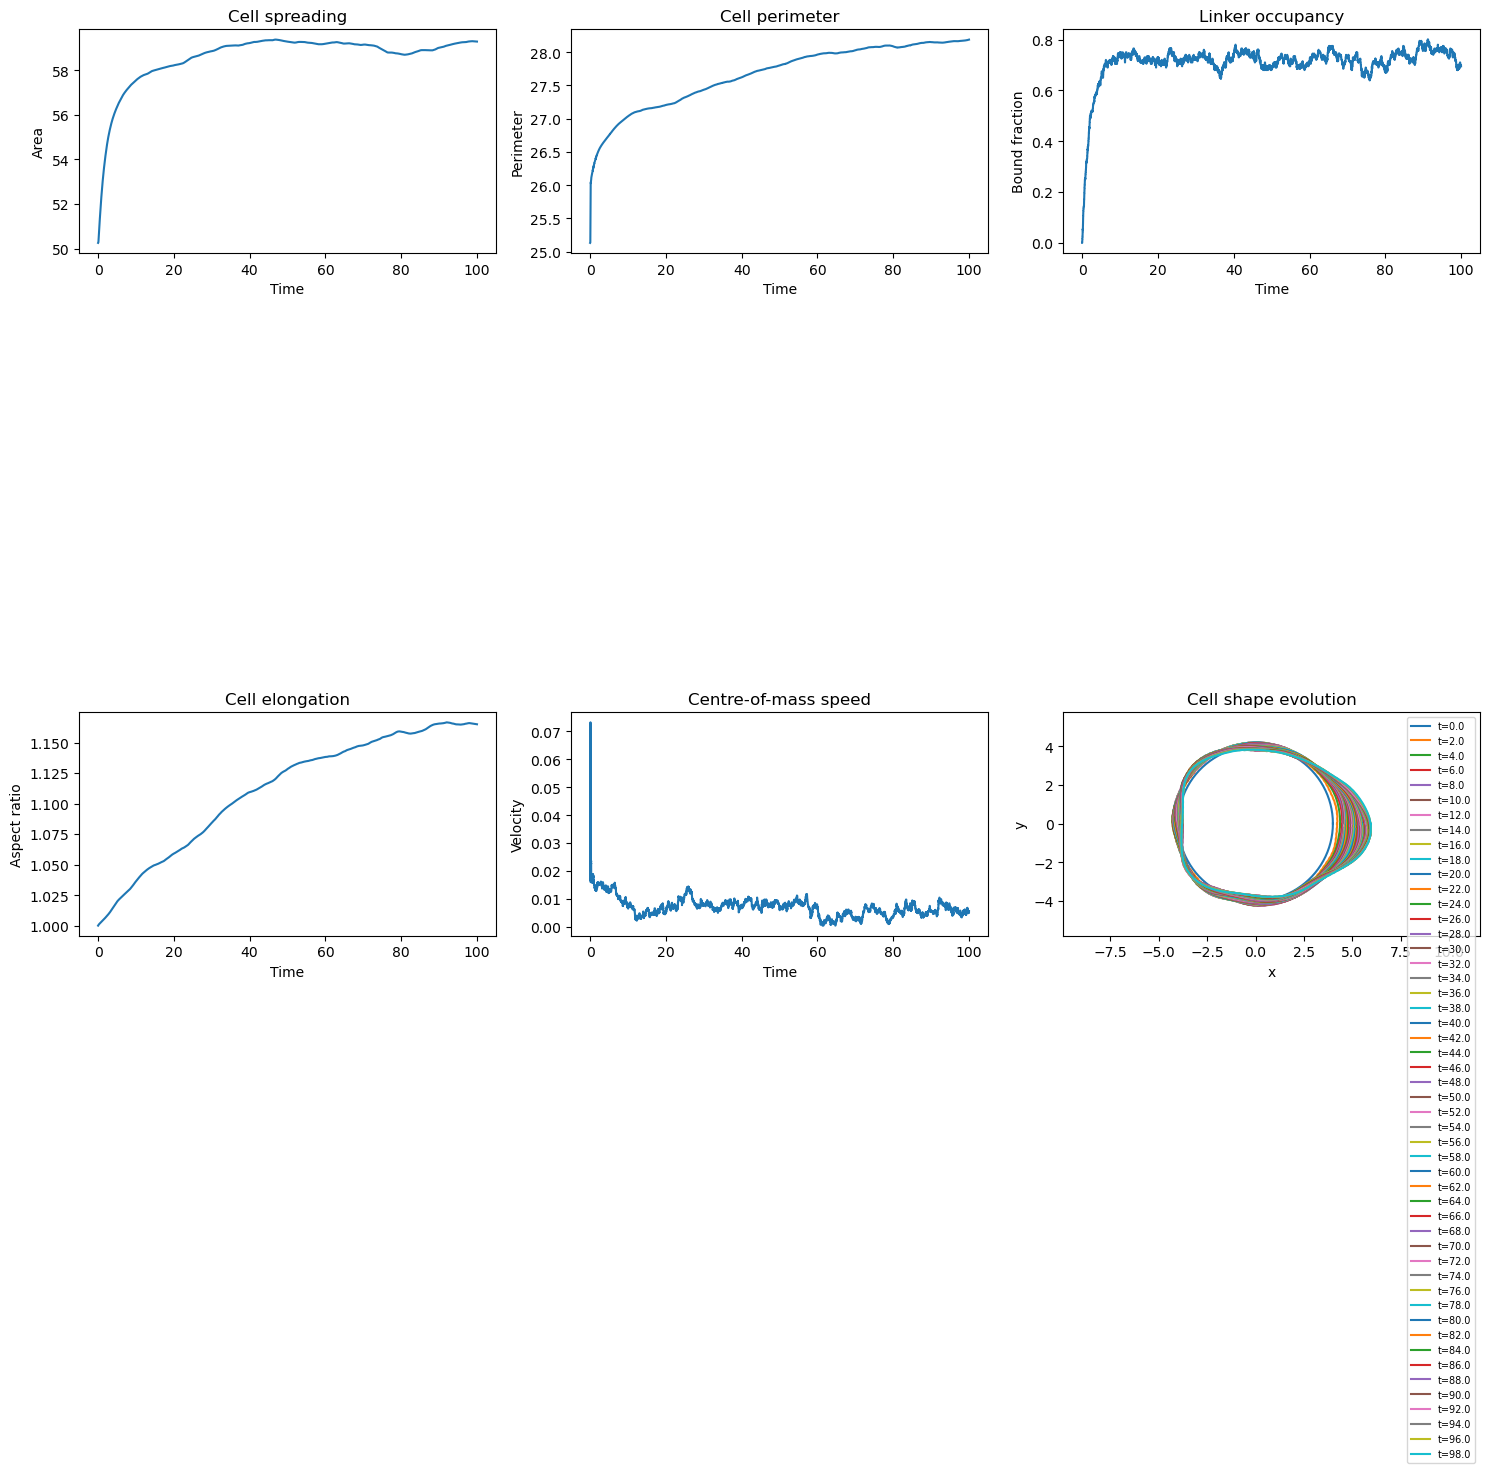

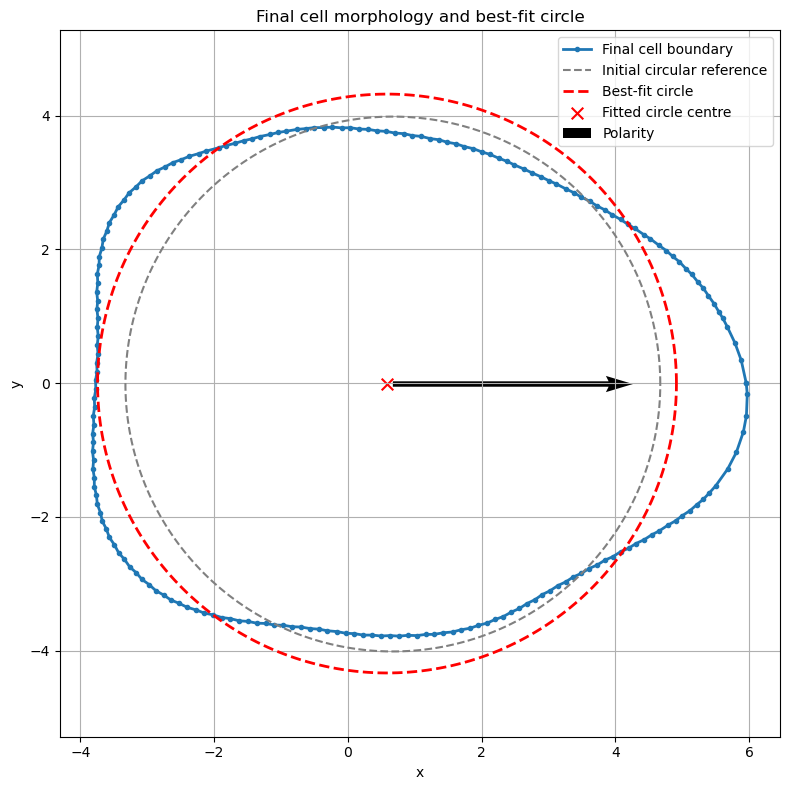


Circle fitting results
----------------------
Fitted circle centre: [ 0.58534731 -0.00623098]
Fitted circle radius: 4.329280200134055
RMS radial deviation: 0.4432629869690076
Relative radial deviation (%): 10.238722523787722
Initial area: 50.257214525005274
Final area: 59.28253458043982
Initial perimeter: 25.131707698913083
Final perimeter: 28.189335437486307
Final linker occupancy: 0.695
Final aspect ratio: 1.164934925356943
Mean migration speed: 0.00718179248231061
Net displacement: 0.6728963225034844


In [10]:
# Initialise a cell as a circular shape of N points.

theta = np.linspace(0, 2*np.pi, N, endpoint=False)
positions = np.column_stack((R0 * np.cos(theta),R0 * np.sin(theta)))



A_initial = cell_area(positions)
P_initial = cell_perimeter(positions)

A0 = A0_factor * A_initial
P0 = P0_factor * P_initial

l_edge = P0 / N

rng = np.random.default_rng(42)

# Initialise a substrate for simulation

grid = np.arange(-substrate_range,  substrate_range + grid_spacing,  grid_spacing)
X, Y = np.meshgrid(grid, grid)

anchors = np.column_stack(( X.ravel(), Y.ravel()))
tree = cKDTree(anchors)

# Initialise linkers at the cell boundaries in unbound state.

state = np.zeros(N, dtype=bool)
# -1 = unbound
anchor_idx = np.full(N, -1, dtype=int)

# Initialise cell properties needed for simulations

area_list = []
perimeter_list = []
occupancy_list = []

centroid_list = []
aspect_ratio_list = []

snapshots = []
snapshot_times = []


# Main simulation body:

for step in range(n_steps):

    # --------------------------------------------------------
    # Calculate mechanical forces
    # --------------------------------------------------------

    F_cell, A, P = calculate_cell_forces(positions)

    F_link, F_active = calculate_linker_forces(positions, state, anchor_idx)

    F_protrusion = calculate_protrusion_force(positions)
    
    
    F_bend = bending_force(positions)
    F_edge = edge_spring_force(positions)

    F_total = (F_cell + F_link + F_active + F_protrusion + F_bend + F_edge)

    # --------------------------------------------------------
    # Overdamped dynamics
    # --------------------------------------------------------

    #In 1D we had the following:
    #velocity = F_total/zeta
    #positions += velocity*dt
    #However, here depends on the size of the region of the cell represented (ds) and so this needs ot be acounted for.
    # Local boundary length represented by each vertex
    normals, ds = calculate_boundary_geometry(positions)

    # Drag proportional to local boundary length
    local_drag = zeta * np.maximum(ds, 1e-12)

    # Overdamped velocity
    velocity = F_total / local_drag[:, None]

    # Update positions
    positions += velocity * dt

    # --------------------------------------------------------
    # Stochastic unbinding
    # --------------------------------------------------------

    bound = np.where(state)[0]

    p_off = k_off*dt

    unbind = rng.random(len(bound)) < p_off

    unbound_indices = bound[unbind]

    state[unbound_indices] = False
    anchor_idx[unbound_indices] = -1

    # --------------------------------------------------------
    # Calculate updated boundary normals
    # --------------------------------------------------------

    normals, ds = calculate_boundary_geometry(positions)

    # --------------------------------------------------------
    # Stochastic binding
    # --------------------------------------------------------

    #p_on_base = k_on*dt

    for i in np.where(~state)[0]:

        # Local front alignment
        alignment = max(0.0, np.dot(normals[i], polarity))

        # Front-biased binding rate
        k_on_local = k_on * (1+beta*alignment)

        p_on_local = k_on_local*dt

        if rng.random() >= p_on_local:
            continue

        # Find nearby substrate points
        candidates = tree.query_ball_point(positions[i], r_capture)

        if len(candidates) == 0:
            continue

        candidates = np.asarray(candidates)

        # Prefer points outside the cell
        vectors = (anchors[candidates]-positions[i])

        outward = (vectors @ normals[i]) > 0

        candidates = candidates[outward]

        if len(candidates) == 0:
            continue

        # Select an attachment point
        selected = rng.choice(candidates)

        state[i] = True
        anchor_idx[i] = selected

    # --------------------------------------------------------
    # Record quantities
    # --------------------------------------------------------

    centroid = cell_centroid(positions)

    # Shape tensor and aspect ratio
    centered = positions-centroid

    shape_tensor = (centered.T @ centered / N)

    eigenvalues = np.linalg.eigvalsh(shape_tensor)

    aspect_ratio = np.sqrt(max(eigenvalues[-1], 1e-12)/ max(eigenvalues[0], 1e-12))

    area_list.append(A)
    perimeter_list.append(P)
    occupancy_list.append(np.mean(state))

    centroid_list.append(centroid)
    aspect_ratio_list.append(aspect_ratio)

    # Save cell shape periodically
    if step % print_every_N_steps == 0:
        snapshots.append(positions.copy())

        snapshot_times.append(step*dt)


# convert the data as needed to np arrays from lists for output plots

time = np.arange(n_steps)*dt

area_list = np.array(area_list)
perimeter_list = np.array(perimeter_list)
occupancy_list = np.array(occupancy_list)

centroid_list = np.array(centroid_list)
aspect_ratio_list = np.array(aspect_ratio_list)

# Centre-of-mass velocity
cm_velocity = np.gradient(centroid_list, dt, axis=0)

speed = np.linalg.norm(cm_velocity, axis=1)


#Create actual plots

fig, ax = plt.subplots(    2, 3, figsize=(15, 10))

# Cell area
ax[0, 0].plot(time, area_list)
ax[0, 0].set_xlabel("Time")
ax[0, 0].set_ylabel("Area")
ax[0, 0].set_title("Cell spreading")

# Perimeter
ax[0, 1].plot(time, perimeter_list)
ax[0, 1].set_xlabel("Time")
ax[0, 1].set_ylabel("Perimeter")
ax[0, 1].set_title("Cell perimeter")

# Linker occupancy
ax[0, 2].plot(time, occupancy_list)
ax[0, 2].set_xlabel("Time")
ax[0, 2].set_ylabel("Bound fraction")
ax[0, 2].set_title("Linker occupancy")

# Aspect ratio
ax[1, 0].plot(time, aspect_ratio_list)
ax[1, 0].set_xlabel("Time")
ax[1, 0].set_ylabel("Aspect ratio")
ax[1, 0].set_title("Cell elongation")

# Migration velocity
ax[1, 1].plot(time, speed)
ax[1, 1].set_xlabel("Time")
ax[1, 1].set_ylabel("Velocity")
ax[1, 1].set_title("Centre-of-mass speed")

# Cell shape evolution
for shape, t in zip(snapshots, snapshot_times):

    closed_shape = np.vstack((        shape, shape[0]    ))

    ax[1, 2].plot(        closed_shape[:, 0],        closed_shape[:, 1],        label=f"t={t:.1f}"    )

ax[1, 2].set_title("Cell shape evolution")
ax[1, 2].set_xlabel("x")
ax[1, 2].set_ylabel("y")
ax[1, 2].axis("equal")
ax[1, 2].legend(fontsize=7)

plt.tight_layout()
plt.show()


#Graphical outputs to verify results

# Fit a circle to the final boundary
fit_centre, fit_radius = fit_circle(positions)

# Generate fitted circle coordinates
theta_fit = np.linspace(0, 2*np.pi, 300)

circle_x = (    fit_centre[0] + fit_radius*np.cos(theta_fit))

circle_y = (    fit_centre[1] + fit_radius*np.sin(theta_fit))

# Calculate final cell centroid
final_centroid = cell_centroid(positions)

# Initial reference circle, translated to final centroid
initial_x = (    final_centroid[0] + R0*np.cos(theta_fit))

initial_y = (    final_centroid[1] + R0*np.sin(theta_fit))

# Plot
plt.figure(figsize=(8, 8))

# Final simulated boundary
final_shape = np.vstack((    positions,    positions[0]))

plt.plot(    final_shape[:, 0],    final_shape[:, 1],    '-o',    markersize=3,    linewidth=2,
         label='Final cell boundary')

# Initial circular reference
plt.plot(    initial_x,    initial_y,    '--',    color='grey',    linewidth=1.5,  
         label='Initial circular reference')

# Best-fit circle
plt.plot(    circle_x,    circle_y,    '--',    color='red',    linewidth=2,    label='Best-fit circle')

# Show fitted circle centre
plt.scatter(    fit_centre[0],    fit_centre[1],    color='red',    marker='x',    s=70,
            label='Fitted circle centre')

# Polarity
plt.quiver(    final_centroid[0],    final_centroid[1],    polarity[0],    polarity[1],    scale=3,
           color='black',    label='Polarity')

plt.xlabel("x")
plt.ylabel("y")
plt.title("Final cell morphology and best-fit circle")

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


#Display the shape change by comparing to the initial circle.

# Radial distance of each boundary point from fitted centre
radial_distances = np.linalg.norm(positions - fit_centre,axis=1)

# Difference between actual radial distances and fitted radius
radial_deviations = radial_distances - fit_radius

# Root mean square radial deviation
RMS_deviation = np.sqrt(np.mean(radial_deviations**2))

# Normalised deviation
relative_deviation = RMS_deviation / fit_radius

print("\nCircle fitting results")
print("----------------------")

print("Fitted circle centre:", fit_centre)
print("Fitted circle radius:", fit_radius)

print("RMS radial deviation:", RMS_deviation)

print(    "Relative radial deviation (%):",    100*relative_deviation)

# Text to check outputs


print("Initial area:", A_initial)
print("Final area:", area_list[-1])

print("Initial perimeter:", P_initial)
print("Final perimeter:", perimeter_list[-1])

print("Final linker occupancy:", occupancy_list[-1])

print("Final aspect ratio:", aspect_ratio_list[-1])

print("Mean migration speed:", np.mean(speed))

print("Net displacement:",
      np.linalg.norm(centroid_list[-1]-centroid_list[0]))


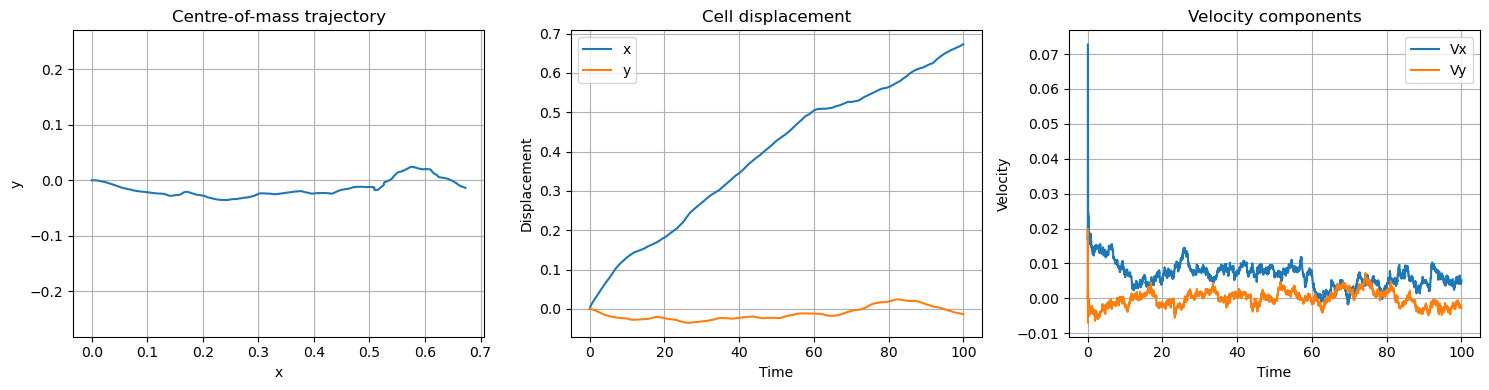

Net displacement: 0.6728963225034844
Mean speed: 0.00718179248231061


In [11]:
# Centre-of-mass displacement
displacement = centroid_list - centroid_list[0]

# Velocity components
vx = np.gradient(centroid_list[:, 0], dt)
vy = np.gradient(centroid_list[:, 1], dt)

# Plot centre-of-mass trajectory
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    centroid_list[:, 0],
    centroid_list[:, 1]
)
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Centre-of-mass trajectory")
axes[0].axis("equal")
axes[0].grid()

axes[1].plot(time, displacement[:, 0], label="x")
axes[1].plot(time, displacement[:, 1], label="y")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Displacement")
axes[1].set_title("Cell displacement")
axes[1].legend()
axes[1].grid()

axes[2].plot(time, vx, label="Vx")
axes[2].plot(time, vy, label="Vy")
axes[2].set_xlabel("Time")
axes[2].set_ylabel("Velocity")
axes[2].set_title("Velocity components")
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.show()

print("Net displacement:",
      np.linalg.norm(displacement[-1]))

print("Mean speed:",
      np.mean(np.sqrt(vx**2 + vy**2)))